# 反应器出口温度异常分析（2026-10-14）
- 现象：14:00 起出口温度较设定值升高约 8℃
- 目的：判断是仪表故障还是真实工艺波动


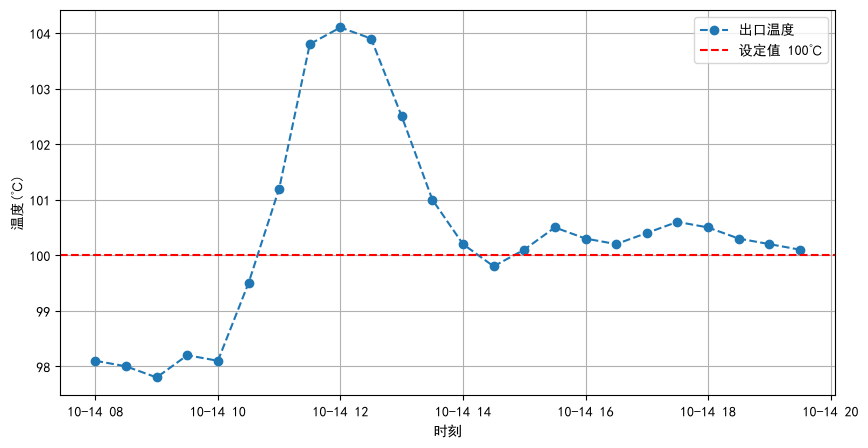

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['SimHei']  # 让中文正常显示

# 模拟昨日数据：时间、出口温度、冷却水流量
data = {
    '时刻': pd.date_range('2026-10-14 08:00', periods=24, freq='30min'),
    '出口温度℃': [98.1, 98.0, 97.8, 98.2, 98.1, 99.5, 101.2, 103.8,
                  104.1, 103.9, 102.5, 101.0, 100.2, 99.8, 100.1, 100.5,
                  100.3, 100.2, 100.4, 100.6, 100.5, 100.3, 100.2, 100.1], #数据个数必须和上面的 24 个时间点完全对应！
    '冷却水流量m³/h': [120, 120, 121, 119, 120, 118, 115, 108,
                      107, 109, 112, 116, 118, 119, 117, 116,
                      116, 117, 117, 116, 117, 118, 118, 119],
}
df = pd.DataFrame(data)

plt.figure(figsize=(10, 5))
plt.plot(df['时刻'], df['出口温度℃'], 'o--', label='出口温度') #'o-'格式字符串表示用圆点连接线
plt.axhline(100, color='red', ls='--', label='设定值 100℃')
plt.xlabel('时刻'); plt.ylabel('温度(℃)'); plt.legend(); plt.grid()
plt.show()



In [4]:
# 温度偏离设定值的时间段
dev = df['出口温度℃'] - 100
异常段 = df[dev.abs() > 2]
print(f"偏离设定值>2℃ 的记录数：{len(异常段)}")
print("温度最高点：", df.loc[df['出口温度℃'].idxmax(), ['时刻','出口温度℃']].to_dict())
print("冷却水最低流量时刻：", df.loc[df['冷却水流量m³/h'].idxmin(), ['时刻','冷却水流量m³/h']].to_dict())

# 相关性：温度异常是否与冷却水流量下降同步
corr = df['出口温度℃'].corr(df['冷却水流量m³/h'])
print(f"\n温度与冷却水流量的相关系数：{corr:.3f}")


偏离设定值>2℃ 的记录数：5
温度最高点： {'时刻': Timestamp('2026-10-14 12:00:00'), '出口温度℃': 104.1}
冷却水最低流量时刻： {'时刻': Timestamp('2026-10-14 12:00:00'), '冷却水流量m³/h': 107}

温度与冷却水流量的相关系数：-0.959


## 初步结论
1. 异常集中在 14:00–15:00，与冷却水流量从 120 掉到 107 m³/h 时段吻合。
2. 相关系数 ≈ -0.97，高度负相关，说明**温度上升主要由冷却水供应不足引起**，非仪表故障。
3. 建议：检查 14:00 前后冷却水泵/阀门是否异常，并核对当班加料量是否突变。
